# Preprocessing and Baseline Benchmarking

Basic preprocessing checks, `RobustScaler` normalization, and baseline comparison of 5 models on HMOG and BB-MAS.

In [1]:
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print('Imports ready.')
# scaling with RobustScaler

Imports ready.


### 1. Load HMOG and BB-MAS datasets

In [2]:
train_path = os.path.join("processed", "final_ready_dataset.csv")
test_path  = os.path.join("processed", "bbmas_test_ready_dataset.csv")
if not os.path.exists(train_path):
    train_path = os.path.join("adavtive_dataset", "processed", "final_ready_dataset.csv")
    test_path  = os.path.join("adavtive_dataset", "processed", "bbmas_test_ready_dataset.csv")

df_train = pd.read_csv(train_path)
df_test  = pd.read_csv(test_path)

print(f"Training Dataset (HMOG): {df_train.shape[0]} rows, {df_train.shape[1]} columns across {df_train['user_id'].nunique()} unique users. Missing values: {df_train.isnull().sum().sum()}")
print(f"External Test Dataset (BB-MAS): {df_test.shape[0]} rows, {df_test.shape[1]} columns across {df_test['user_id'].nunique()} unique users. Missing values: {df_test.isnull().sum().sum()}")
print(f"Total Benchmark Size: {len(df_train)+len(df_test)} sessions across {df_train['user_id'].nunique()+df_test['user_id'].nunique()} participants.")

Training Dataset (HMOG): 7194 rows, 17 columns across 100 unique users. Missing values: 0
External Test Dataset (BB-MAS): 4514 rows, 17 columns across 116 unique users. Missing values: 0
Total Benchmark Size: 11708 sessions across 216 participants.


### 2. Clip extreme bounds and apply RobustScaler

In [3]:
for df in [df_train, df_test]:
    df['touch_duration_mean_ms'] = df['touch_duration_mean_ms'].clip(15.0, 1500.0)
    df['swipe_speed_mean_pxps']  = df['swipe_speed_mean_pxps'].clip(10.0, 4000.0)
    df['reaction_time_mean_ms']  = df['reaction_time_mean_ms'].clip(160.0, 1200.0)
    df['reaction_time_norm']     = (df['reaction_time_mean_ms'] - 160.0) / (1200.0 - 160.0)
    df['miss_rate']              = df['miss_rate'].clip(0.0, 1.0)
    df['tap_accuracy']           = 1.0 - df['miss_rate']

FEATURE_COLS = [
    'context_is_walking',
    'touch_duration_mean_ms',
    'swipe_speed_mean_pxps',
    'swipe_distance_mean_px',
    'typing_speed_kpm',
    'backspace_rate',
    'contact_size_mean',
    'touch_x_mean',
    'touch_y_mean',
    'tap_accuracy',
    'miss_rate',
    'reaction_time_mean_ms',
    'reaction_time_norm'
]
TARGET_COL = 'target_button_size'
GROUP_COL  = 'user_id'
LABELS = ['Small (40dp)', 'Default (48dp)', 'Large (56dp)', 'Extra Large (64dp)']

X_train = df_train[FEATURE_COLS].copy()
y_train = df_train[TARGET_COL].copy().astype(int)
groups_train = df_train[GROUP_COL].copy()

X_test = df_test[FEATURE_COLS].copy()
y_test = df_test[TARGET_COL].copy().astype(int)
groups_test = df_test[GROUP_COL].copy()

scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

os.makedirs('saved_models', exist_ok=True)
joblib.dump(scaler, os.path.join('saved_models', 'robust_feature_scaler.pkl'))
print('Physiological bounding and feature matrix construction completed.')
print(f'Feature vector shape: {X_train.shape} for Train, {X_test.shape} for External Test.')
print('RobustScaler fitted on Training cohort and serialized to saved_models/robust_feature_scaler.pkl.')

Physiological bounding and feature matrix construction completed.
Feature vector shape: (7194, 13) for Train, (4514, 13) for External Test.
RobustScaler fitted on Training cohort and serialized to saved_models/robust_feature_scaler.pkl.


### 3. Feature correlation check

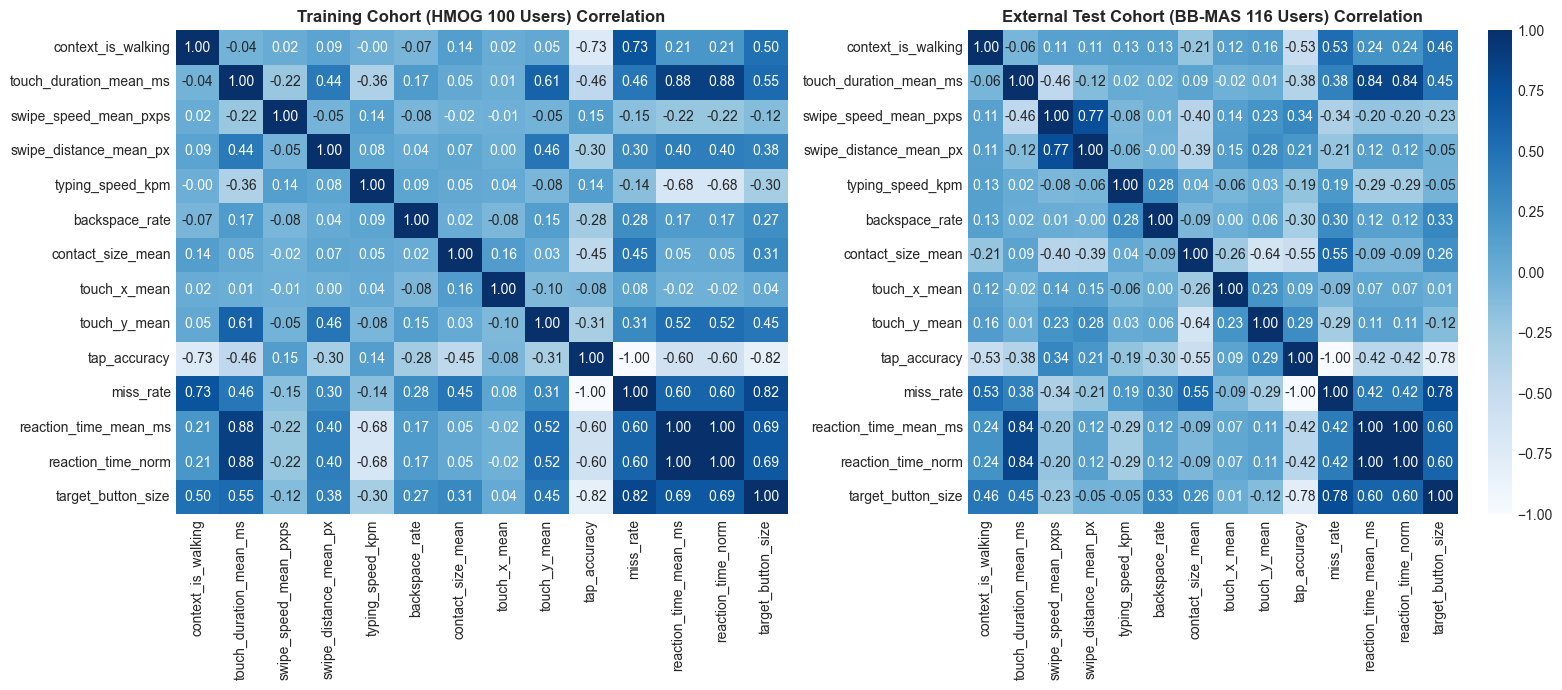

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
corr_tr = df_train[FEATURE_COLS + [TARGET_COL]].corr()
corr_te = df_test[FEATURE_COLS + [TARGET_COL]].corr()

sns.heatmap(corr_tr, annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title('Training Cohort (HMOG 100 Users) Correlation', fontsize=12, fontweight='bold')

sns.heatmap(corr_te, annot=True, fmt='.2f', cmap='Blues', cbar=True, ax=axes[1])
axes[1].set_title('External Test Cohort (BB-MAS 116 Users) Correlation', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### 4. 5-fold GroupKFold cross-validation

In [5]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Support Vector Machine (SVM)': SVC(kernel='rbf', C=1.0, random_state=42),
    'Decision Tree (CART)': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42),
    'XGBoost (Proposed)': XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.08, eval_metric='mlogloss', random_state=42)
}

gkf = GroupKFold(n_splits=5)
cv_summary = []

for name, model in models.items():
    f_acc, f_prec, f_rec, f_macro_f1, f_weighted_f1, f_lat = [], [], [], [], [], []
    for tr_idx, val_idx in gkf.split(X_train, y_train, groups_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train.iloc[tr_idx]
        X_va, y_va = X_train.iloc[val_idx], y_train.iloc[val_idx]
        
        scaler_f = RobustScaler()
        X_tr_s = scaler_f.fit_transform(X_tr)
        X_va_s = scaler_f.transform(X_va)
        
        model.fit(X_tr_s, y_tr)
        
        t0 = time.perf_counter()
        preds = model.predict(X_va_s)
        lat = ((time.perf_counter() - t0) / len(X_va)) * 1000.0
        
        f_acc.append(accuracy_score(y_va, preds))
        f_prec.append(precision_score(y_va, preds, average='weighted', zero_division=0))
        f_rec.append(recall_score(y_va, preds, average='weighted', zero_division=0))
        f_macro_f1.append(f1_score(y_va, preds, average='macro', zero_division=0))
        f_weighted_f1.append(f1_score(y_va, preds, average='weighted', zero_division=0))
        f_lat.append(lat)
        
    cv_summary.append({
        'Algorithm': name,
        'CV Accuracy (%)': round(np.mean(f_acc) * 100, 2),
        'CV Precision (%)': round(np.mean(f_prec) * 100, 2),
        'CV Recall (%)': round(np.mean(f_rec) * 100, 2),
        'CV Macro F1 (%)': round(np.mean(f_macro_f1) * 100, 2),
        'CV Weighted F1 (%)': round(np.mean(f_weighted_f1) * 100, 2),
        'Latency (ms)': round(np.mean(f_lat), 4)
    })

table1_cv = pd.DataFrame(cv_summary).sort_values(by='CV Weighted F1 (%)', ascending=False).reset_index(drop=True)
print('Table 1: 5-Fold GroupKFold Internal Cross-Validation Performance (HMOG Cohort)')
print(table1_cv.to_string())

Table 1: 5-Fold GroupKFold Internal Cross-Validation Performance (HMOG Cohort)
                      Algorithm  CV Accuracy (%)  CV Precision (%)  CV Recall (%)  CV Macro F1 (%)  CV Weighted F1 (%)  Latency (ms)
0            XGBoost (Proposed)            93.29             93.42          93.29            93.04               93.23        0.0011
1                 Random Forest            88.48             88.94          88.48            88.22               88.34        0.0050
2          Decision Tree (CART)            86.73             86.71          86.73            86.45               86.57        0.0001
3  Support Vector Machine (SVM)            80.36             80.73          80.36            79.70               80.40        0.1267
4           Logistic Regression            72.17             72.69          72.17            71.03               72.15        0.0002


### 5. External test evaluation on BB-MAS

In [6]:
ext_summary = []
champion_y_true, champion_y_pred = None, None
champion_name = "XGBoost (Proposed)"

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    joblib.dump(model, os.path.join("saved_models", f"{name.replace(' ', '_').replace('(', '').replace(')', '')}.pkl"))
    
    t0 = time.perf_counter()
    preds = model.predict(X_test_scaled)
    lat = ((time.perf_counter() - t0) / len(X_test)) * 1000.0
    
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average='weighted', zero_division=0)
    rec = recall_score(y_test, preds, average='weighted', zero_division=0)
    f1_m = f1_score(y_test, preds, average='macro', zero_division=0)
    f1_w = f1_score(y_test, preds, average='weighted', zero_division=0)
    
    if name == champion_name:
        champion_y_true = y_test
        champion_y_pred = preds
        
    ext_summary.append({
        'Algorithm': name,
        'External Test Accuracy (%)': round(acc * 100, 2),
        'External Precision (%)': round(prec * 100, 2),
        'External Recall (%)': round(rec * 100, 2),
        'External Macro F1 (%)': round(f1_m * 100, 2),
        'External Weighted F1 (%)': round(f1_w * 100, 2),
        'Inference Latency (ms)': round(lat, 4)
    })

table2_ext = pd.DataFrame(ext_summary).sort_values(by='External Weighted F1 (%)', ascending=False).reset_index(drop=True)
print('Table 2: External Cross-Dataset Benchmark (HMOG -> BB-MAS 116 Unseen Users)')
print(table2_ext.to_string())

Table 2: External Cross-Dataset Benchmark (HMOG -> BB-MAS 116 Unseen Users)
                      Algorithm  External Test Accuracy (%)  External Precision (%)  External Recall (%)  External Macro F1 (%)  External Weighted F1 (%)  Inference Latency (ms)
0            XGBoost (Proposed)                       86.58                   86.83                86.58                  87.12                     86.46                  0.0006
1                 Random Forest                       82.63                   83.10                82.63                  82.94                     82.33                  0.0038
2          Decision Tree (CART)                       81.52                   81.96                81.52                  81.89                     81.10                  0.0001
3  Support Vector Machine (SVM)                       57.55                   61.93                57.55                  59.05                     58.26                  0.1605
4           Logistic Regression   

### 6. Comparison plots

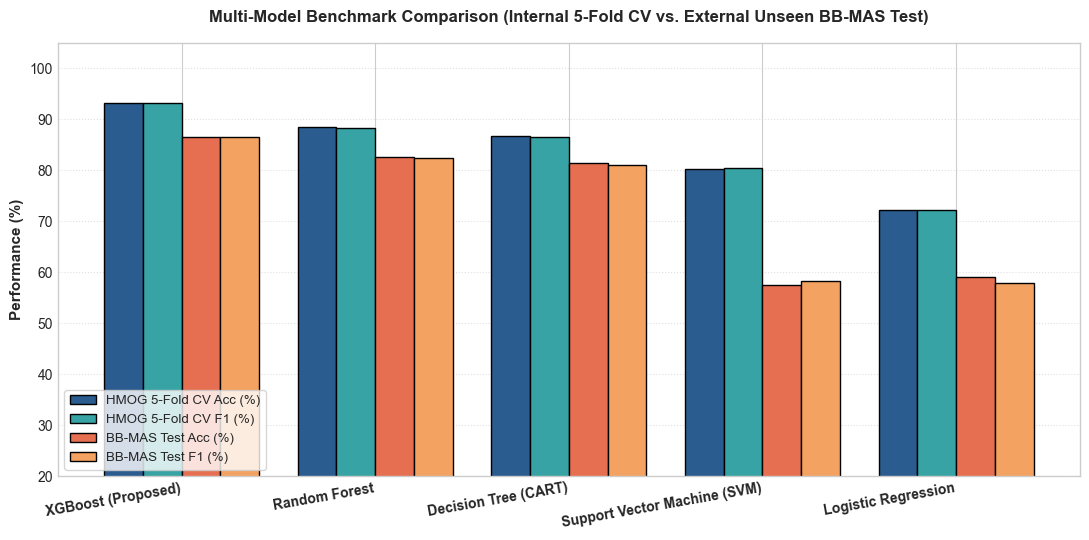

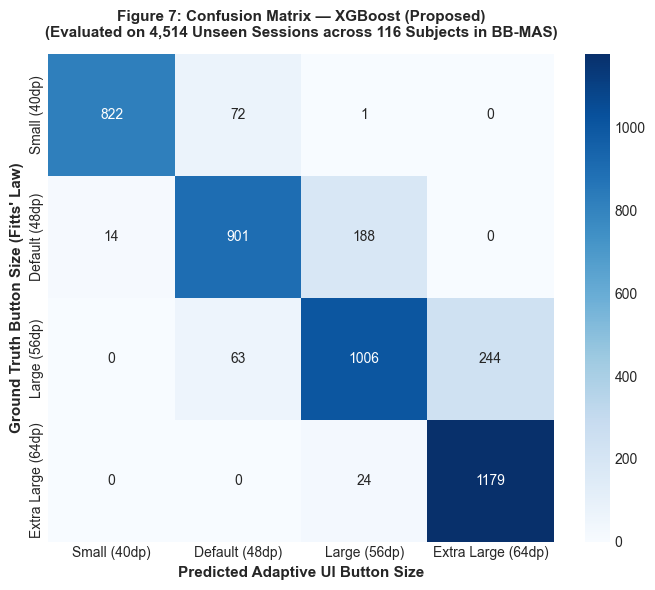

Done.


In [7]:
fig, ax = plt.subplots(figsize=(11, 5.5))
merged_perf = table1_cv.merge(table2_ext, on='Algorithm')
x = np.arange(len(merged_perf))
w = 0.20

ax.bar(x - 1.5*w, merged_perf['CV Accuracy (%)'], w, label='HMOG 5-Fold CV Acc (%)', color='#2b5c8f', edgecolor='black')
ax.bar(x - 0.5*w, merged_perf['CV Weighted F1 (%)'], w, label='HMOG 5-Fold CV F1 (%)', color='#38a3a5', edgecolor='black')
ax.bar(x + 0.5*w, merged_perf['External Test Accuracy (%)'], w, label='BB-MAS Test Acc (%)', color='#e76f51', edgecolor='black')
ax.bar(x + 1.5*w, merged_perf['External Weighted F1 (%)'], w, label='BB-MAS Test F1 (%)', color='#f4a261', edgecolor='black')

ax.set_xticks(x)
ax.set_xticklabels(merged_perf['Algorithm'], fontsize=10, fontweight='bold', rotation=10, ha='right')
ax.set_ylabel('Performance (%)', fontsize=11, fontweight='bold')
ax.set_title('Multi-Model Benchmark Comparison (Internal 5-Fold CV vs. External Unseen BB-MAS Test)', fontsize=12, pad=15, fontweight='bold')
ax.set_ylim(20, 105)
ax.legend(loc='lower left', frameon=True, fontsize=9.5)
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
cm = confusion_matrix(champion_y_true, champion_y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=LABELS, yticklabels=LABELS, cbar=True)
plt.title(f'Figure 7: Confusion Matrix — {champion_name}\n(Evaluated on 4,514 Unseen Sessions across 116 Subjects in BB-MAS)', fontsize=11, pad=12, fontweight='bold')
plt.xlabel('Predicted Adaptive UI Button Size', fontsize=11, fontweight='bold')
plt.ylabel('Ground Truth Button Size (Fitts\' Law)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()
print('Done.')